# CCF estimators on a generator with known truth: which reference date biases the EAD

**Question:** When the drawing of revolving lines accelerates before default, which reference-date design and which treatment of the outliers recover the known conversion factor of a generated book, and how large is the bias of each against a tolerance of 0.02?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the factor, its designs and its treatments)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- read the six acceleration levels of the C09 generator and say what its known CCF is at each;
- explain the two aggregations of a set of factors, the mean and the pooled ratio, and why they differ when the lines with the most undrawn amount draw least;
- compute the bias of an estimator against the known truth with `ccf_bias`, read `ccf_estimator_bias` (statistic, p-value, tolerance and light) and say why a significant bias inside the tolerance stays green;
- run the three reference-date designs and the treatments of a factor outside [0, 1] on ten generated replications at each level, and say how much of the result is a property of the generator's own horizon;
- fit the two EAD models that need no factor, `fit_direct_ead` and `fit_utilisation_change`, on generated lines and see why the first cannot predict above the limit.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Put the pipeline on the import path, import the packages and print their versions
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf
from riskvalidation.validation import lgd_ead as lgd_tests

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator, params

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Seven committed artifacts of case C09, the exposure at default of revolving credit lines: the generator artifact `models-generator.json` and the variants `level-0.json` to `level-5.json`, one per acceleration level. C09 has **a known truth**: its lines are produced by a generator whose marginal distributions follow the Federal Reserve's 2025 hypothetical card portfolios, and whose conversion factor is its own parameter. At level 0 the undrawn amount is drawn at a constant rate over the twelve months before the default. From level 1 on, the drawing rate accelerates in the last six months by a factor of 1.25 up to 3, which raises the known CCF, because the balance rises faster near the default. The data are synthetic and say nothing about any lender.

The artifacts hold the replication plan (the seeds) and the committed estimates over twenty test replications of 50,000 facilities. This notebook does not read those estimates to answer its question: it draws ten of the test replications again with the case's own generator and the plan's seeds, estimates every design on them with the engine, and only draws the committed twenty-replication biases as a dashed reference in the figure of step 3. Nothing is written to disk.

In [2]:
# Load the generator artifact and the six levels; print the plan and the known CCF of each level
derived = ROOT / "data" / "derived" / "C09"
gen = json.loads((derived / "models-generator.json").read_text(encoding="utf-8"))["fit"]
levels = [json.loads((derived / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
plan = gen["replications_plan"]
print("baked by riskvalidation:", sorted({v["provenance"]["riskvalidation_version"] for v in levels}))
print("installed:", rv.__version__)
n_dev, n_test = len(plan["development_seeds"]), len(plan["test_seeds"])
print(f"committed plan: {n_dev} development + {n_test} test | {plan['n_facilities']:,} facilities")
print(f"{'level':>6s} {'acceleration':>14s} {'known CCF':>16s}")
for lv in gen["levels"]:
    print(f"{lv['level']:6d} {lv['acceleration_factor']:14.2f} {params.known_ccf(lv['level'], 12):16.6f}")

baked by riskvalidation: ['1.0.1']
installed: 1.0.1
committed plan: 20 development + 20 test | 50,000 facilities
 level   acceleration        known CCF
     0           1.00         0.600000
     1           1.25         0.634252
     2           1.50         0.664272
     3           2.00         0.714173
     4           2.50         0.753697
     5           3.00         0.785540


## Method

### Step 1: two ways to combine the factors

Given the factors $c_i$ of $N$ defaulters and their undrawn amounts $U_i = L_i - E_i$ at the reference date, the engine's `aggregate_ccf(ccf, undrawn, aggregator)` offers two summaries:

$$\text{mean} = \frac{1}{N}\sum_i c_i, \qquad \text{pooled} = \frac{\sum_i c_i\,U_i}{\sum_i U_i} = \frac{\sum_i (EAD_i - E_i)}{\sum_i (L_i - E_i)}$$

(Source: the docstring of `aggregate_ccf`; undefined factors are excluded and a set with no defined factor raises an error.) The mean gives every defaulter the same weight; the pooled ratio gives every unit of undrawn amount the same weight, so it is the share of the undrawn *currency* that was drawn. The two differ when the factor depends on the size of the undrawn amount. The cell invents six defaulters, three with a small undrawn amount that draw it all and three with a large one that draw little, and prints both.

In [3]:
# Six invented defaulters, small undrawn amounts drawn fully and large ones drawn little: mean and pooled
factor = np.array([1.0, 1.0, 1.0, 0.2, 0.2, 0.2])
undrawn = np.array([10.0, 10.0, 10.0, 1_000.0, 1_000.0, 1_000.0])
mean_c = ccf.aggregate_ccf(factor, undrawn, "mean")
pooled_c = ccf.aggregate_ccf(factor, undrawn, "pooled")
print(f"mean = {mean_c:.4f} | pooled = {pooled_c:.4f}")
weighted, total = np.sum(factor * undrawn), np.sum(undrawn)
print(f"pooled by hand: sum(c * U) / sum(U) = {weighted:.1f} / {total:.1f} = {weighted / total:.4f}")

mean = 0.6000 | pooled = 0.2079
pooled by hand: sum(c * U) / sum(U) = 630.0 / 3030.0 = 0.2079


### Step 2: the bias of an estimator and its test

A generator knows the true CCF, so an estimator can be scored: `ccf_bias(estimate, truth)` is $\text{estimate} - \text{truth}$, signed and not clipped. C09 repeats the experiment $R = 20$ times and the engine's `ccf_estimator_bias(estimates, truth, tolerance)` summarises the replications. With $e_r = \hat c_r - c$ the error of replication $r$:

$$\text{bias} = \bar e, \qquad \text{RMSE} = \sqrt{\overline{e^2}}, \qquad t = \frac{\bar e}{s_e/\sqrt{R}} \; (R - 1 \text{ degrees of freedom}), \qquad p = 2\,P(T_{R-1} > |t|)$$

The light depends only on the bias and a tolerance, not on the p-value: green when $|\text{bias}| \le$ tolerance, amber up to twice it, red above; the p-value is informative, so a statistically significant bias inside the tolerance stays green and the view shows both (all from the function's docstring, a Contraste internal gate and not a regulatory one). The C09 tolerance is 0.02.

The next cell invents the 20 estimates of two estimators against a truth of 0.6: one with a small and steady bias of -0.015, which is significant and inside the tolerance, and one with a bias of -0.05. These 40 numbers are made up to show how the test reads.

In [4]:
# Score two invented estimators against a known truth of 0.6 with a tolerance of 0.02
light = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
rng = np.random.default_rng(11)
truth = 0.6
steady = truth - 0.015 + rng.normal(0.0, 0.004, 20)
poor = truth - 0.05 + rng.normal(0.0, 0.02, 20)
for label, est in (("steady, bias -0.015", steady), ("poor, bias -0.05", poor)):
    res = lgd_tests.ccf_estimator_bias(est, truth, tolerance=0.02, model_id=label)
    direct_bias = ccf.ccf_bias(est.mean(), truth)
    print(f"{label:28s} bias {res.metric:8.4f} (ccf_bias {direct_bias:8.4f}) t={res.statistic:8.3f}")
    inside = res.extras["within_tolerance"]
    rmse = res.extras["rmse"]
    print(f"{'':28s} p={res.p_value:.2e} RMSE={rmse:.4f} within tolerance={inside} {light[res.light.value]}")

steady, bias -0.015          bias  -0.0142 (ccf_bias  -0.0142) t= -19.980
                             p=3.24e-14 RMSE=0.0145 within tolerance=True green
poor, bias -0.05             bias  -0.0572 (ccf_bias  -0.0572) t= -15.166
                             p=4.54e-12 RMSE=0.0595 within tolerance=False red


### Step 3: run the generator and estimate every design

Now the real experiment, small enough to run in the notebook. For each of ten test seeds of the committed plan the cell draws the population of 50,000 facilities, realises it at each of the six acceleration levels, reads the factors of every defaulter under the three designs (`reference_indices` and `ccf_observations` through the case's `observe`) and summarises them with `aggregate_ccf` as a pooled ratio and as a mean. The true CCF of each level is the closed form of the generator, `params.known_ccf(level, 12)`, and the bias of an estimate is `ccf_bias(estimate, truth)`. The cell keeps the level 3 observations of the fixed-horizon design for step 5 and prints the mean bias over the ten replications.

In [5]:
# Draw ten replications, estimate the three designs at six levels and print the mean pooled bias
DESIGNS = ("fixed-horizon", "cohort", "variable-horizon")
shown = {"fixed-horizon": "fixed", "cohort": "cohort", "variable-horizon": "variable"}
estimates = {(lv, d, a): [] for lv in range(6) for d in DESIGNS for a in ("mean", "pooled")}
level3 = []
for seed in plan["test_seeds"][:10]:
    population = generator.draw_population(seed, 50_000)
    for lv in range(6):
        lines = generator.realise(population, lv)
        for d in DESIGNS:
            obs = estimators.observe(lines, d)
            for a in ("mean", "pooled"):
                estimates[(lv, d, a)].append(ccf.aggregate_ccf(obs.ccf, obs.undrawn, a))
            if lv == 3 and d == "fixed-horizon":
                level3.append(obs)
truth = [params.known_ccf(lv, 12) for lv in range(6)]
bias = {k: np.mean([ccf.ccf_bias(e, truth[k[0]]) for e in v]) for k, v in estimates.items()}
print(f"{'level':>6s} {'known CCF':>12s} " + " ".join(f"{shown[d]:>9s}" for d in DESIGNS))
for lv in range(6):
    print(f"{lv:6d} {truth[lv]:12.4f} " + " ".join(f"{bias[(lv, d, 'pooled')]:9.4f}" for d in DESIGNS))
mean_bias = ", ".join(f"{bias[(lv, 'fixed-horizon', 'mean')]:.4f}" for lv in range(6))
print("bias of the mean of the factors, fixed horizon, levels 0 to 5:", mean_bias)

 level    known CCF     fixed    cohort  variable
     0       0.6000   -0.0228   -0.2615   -0.1835
     1       0.6343   -0.0228   -0.2525   -0.1752
     2       0.6643   -0.0226   -0.2437   -0.1673
     3       0.7142   -0.0218   -0.2270   -0.1530
     4       0.7537   -0.0209   -0.2121   -0.1405
     5       0.7855   -0.0198   -0.1988   -0.1298
bias of the mean of the factors, fixed horizon, levels 0 to 5: -0.0005, -0.0004, -0.0004, -0.0002, -0.0001, -0.0000


The figure draws the pooled-ratio bias of each design against the acceleration level, with the tolerance band of plus and minus 0.02 and, as dashed lines, the biases that the artifacts committed over twenty replications. The pooled ratio is the aggregation to read for the cohort and variable-horizon designs: the bias of their plain mean is erratic and its sample variation is wide, because a ratio with a small undrawn amount in the denominator is unbounded and a few such lines dominate an unweighted mean.

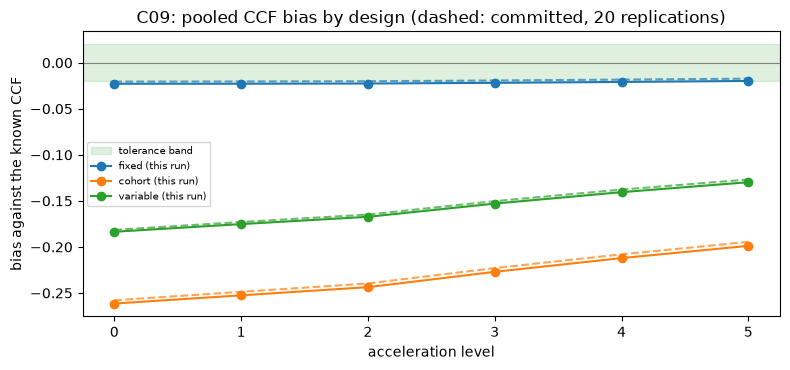

In [6]:
# Draw the pooled bias of the three designs against the level, with the tolerance band and the committed ones
tolerance = levels[0]["outputs"]["ccf_by_design"]["tolerance"]
tables = [doc["outputs"]["ccf_by_design"]["rows"] for doc in levels]
rows = [{(r["design"], r["treatment"], r["estimator"]): r for r in table} for table in tables]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.axhspan(-tolerance, tolerance, color="tab:green", alpha=0.15, label="tolerance band")
for k, design in enumerate(DESIGNS):
    mine = [bias[(lv, design, "pooled")] for lv in range(6)]
    ax.plot(range(6), mine, marker="o", color=f"C{k}", label=f"{shown[design]} (this run)")
    committed = [row[(design, "none", "pooled")]["bias"] for row in rows]
    ax.plot(range(6), committed, linestyle="--", color=f"C{k}", alpha=0.7)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("acceleration level")
ax.set_ylabel("bias against the known CCF")
ax.set_title("C09: pooled CCF bias by design (dashed: committed, 20 replications)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Read the figure in two steps. The fixed-horizon design stays at the lower edge of the green band at every level, within about 0.003 of the committed dashed line: ten replications land where twenty did. One caution before reading it as a ranking: the generator defines its known CCF over the twelve months before the default, which is exactly the horizon of the `fixed-horizon` design. That design therefore measures the quantity the truth is defined for, and its small bias is partly by construction. The cohort and variable-horizon designs put the reference date later and measure the share of a smaller undrawn amount, so against this truth they read low, by an amount that narrows as the acceleration grows. What the figure shows is how large the gap between designs is on the same defaults, not that one design is correct in general.

### Step 4: the bias test and its light, on the replications

The engine's `ccf_estimator_bias(estimates, truth, tolerance)` summarises the replications of one estimator: the bias, the RMSE, a t statistic and a p-value, and a light set only by the bias against the tolerance. The cell applies it at level 3 to the three designs, with the pooled ratio computed in step 3, and to the mean of the factors of the fixed-horizon design. The p-value is informative: a statistically significant bias inside the tolerance stays green.

In [7]:
# Run ccf_estimator_bias on the ten replications of level 3 for four estimators
cases = [(d, "pooled") for d in DESIGNS] + [("fixed-horizon", "mean")]
print(f"known CCF of level 3: {truth[3]:.4f} | tolerance {tolerance}")
for d, a in cases:
    reps = np.array(estimates[(3, d, a)])
    res = lgd_tests.ccf_estimator_bias(reps, truth[3], tolerance=tolerance, model_id=f"{d}-{a}")
    head = f"{shown[d]:9s} {a:7s} bias {res.metric:8.4f}  t={res.statistic:8.2f}"
    print(head, f" p={res.p_value:.2e}  RMSE={res.extras['rmse']:.4f}  {light[res.light.value]}")

known CCF of level 3: 0.7142 | tolerance 0.02
fixed     pooled  bias  -0.0218  t=   -4.72  p=1.09e-03  RMSE=0.0259  amber
cohort    pooled  bias  -0.2270  t=  -53.23  p=1.47e-12  RMSE=0.2274  red
variable  pooled  bias  -0.1530  t=  -30.74  p=2.00e-10  RMSE=0.1537  red
fixed     mean    bias  -0.0002  t=   -0.08  p=9.34e-01  RMSE=0.0089  green


### Step 5: the treatments of a factor outside [0, 1]

Notebook 02 introduced the treatments of `treat_ccf`. Here is what each does to the bias at level 3, with the fixed-horizon design and both aggregations, on the ten replications kept in step 3. `censor` drops the observations outside [0, 1], which removes the lines that drew more than their undrawn amount and so pulls the estimate down; `floor-cap` clips them, which the engine documents as biasing the EAD. The cell applies each treatment to every replication, aggregates with the engine and reports the mean bias, and the figure draws it against the tolerance band.

In [8]:
# Apply three treatments to the fixed-horizon observations of level 3 and aggregate with both estimators
treatments = ("none", "censor", "floor-cap")
by_treatment = {(t, a): [] for t in treatments for a in ("mean", "pooled")}
dropped = {t: [] for t in treatments}
for obs in level3:
    for t in treatments:
        kept = estimators.treat(obs, t)
        dropped[t].append(kept.n_dropped)
        for a in ("mean", "pooled"):
            by_treatment[(t, a)].append(ccf.aggregate_ccf(kept.values, kept.undrawn, a))
tbias = {k: np.mean([ccf.ccf_bias(e, truth[3]) for e in v]) for k, v in by_treatment.items()}
print(f"{'treatment':12s} {'dropped':>12s} {'mean':>10s} {'pooled':>10s}")
for t in treatments:
    print(f"{t:12s} {np.mean(dropped[t]):12.0f} {tbias[(t, 'mean')]:10.4f} {tbias[(t, 'pooled')]:10.4f}")
print(f"share of factors below 0: {estimators.treat(level3[0], 'none').n_below_zero / level3[0].ccf.size:.4f}")

treatment         dropped       mean     pooled
none                  432    -0.0002    -0.0218
censor                657    -0.0547    -0.0701
floor-cap             432    -0.0132    -0.0329
share of factors below 0: 0.0079


The table gives the mean bias of each treatment over the ten replications, with the number of observations each one drops. The figure puts the same numbers against the tolerance band, for the mean of the factors and for the pooled ratio side by side.

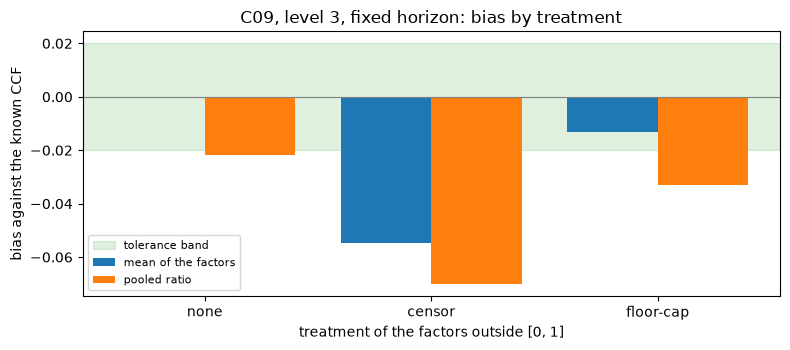

In [9]:
# Draw the bias of each treatment against the tolerance band
fig, ax = plt.subplots(figsize=(8, 3.6))
positions = np.arange(len(treatments))
ax.axhspan(-tolerance, tolerance, color="tab:green", alpha=0.15, label="tolerance band")
as_mean = [tbias[(t, "mean")] for t in treatments]
as_pooled = [tbias[(t, "pooled")] for t in treatments]
ax.bar(positions - 0.2, as_mean, width=0.4, color="tab:blue", label="mean of the factors")
ax.bar(positions + 0.2, as_pooled, width=0.4, color="tab:orange", label="pooled ratio")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xticks(positions)
ax.set_xticklabels(treatments)
ax.set_xlabel("treatment of the factors outside [0, 1]")
ax.set_ylabel("bias against the known CCF")
ax.set_title("C09, level 3, fixed horizon: bias by treatment")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Leaving the factors as they are keeps the mean of the factors on the truth and the pooled ratio just outside the band. Censoring is the damaging choice: it removes the lines that drew their whole undrawn amount and more, about 225 more observations per replication than the undefined ones, and both aggregations fall well outside the tolerance. Clipping to [0, 1] keeps the mean inside the band but moves the pooled ratio further under the truth than leaving the factors alone, because the amounts above the limit are cut at 1. A treatment that looks hygienic, discarding the awkward values, is thus the one that biases the estimate most, and the bias is reported by the test of step 4 rather than hidden.

### Step 6: EAD models without a factor

The research asks whether a model of the EAD itself, with no factor, does better than the factor (Tong et al. 2016, as the engine's docstring names it). The engine fits two:

- `fit_direct_ead(X, ead, limit)`: a fractional logit of $EAD / L$ on the covariates. An EAD above the limit gives a ratio above 1; it is clipped to 1 for the fit and **counted** in `extras`, never silently. The engine notes that the zero-adjusted gamma mixture of Tong et al. (2016) is not in this version.
- `fit_utilisation_change(X, drawn_ref, drawn_default, limit_ref)`: least squares on the change of utilisation $(E(t_d) - E(t_r)) / L(t_r)$, which has no undrawn amount in the denominator.

`predict_ead` returns for the first $L$ times the fitted ratio, inside $[0, L]$, and for the second $E(t_r) + L\,\hat\Delta$, not clipped. The cell fits both on three development replications of level 3 and predicts the ten test replications kept in step 3, with the covariates the case uses (utilisation, the logarithm of the limit and the credit score).

In [10]:
# Fit the two factor-free EAD models on development replications of level 3 and predict the test replications
dev = [generator.generate(seed, 3, 50_000) for seed in plan["development_seeds"][:3]]
train = estimators.join([estimators.observe(d, "fixed-horizon") for d in dev])
test = estimators.join(level3)
cols = estimators.FEATURE_NAMES
direct = ccf.fit_direct_ead(estimators.features(train), train.ead, train.limit_ref, cols)
change = ccf.fit_utilisation_change(estimators.features(train), train.drawn_ref, train.ead, train.limit_ref, cols)
X_test = estimators.features(test)
pred_direct = ccf.predict_ead(direct, X_test, test.drawn_ref, test.limit_ref)
pred_change = ccf.predict_ead(change, X_test, test.drawn_ref, test.limit_ref)
print(f"training observations: {train.ead.size:,} | test observations: {test.ead.size:,}")
print(f"mean realised EAD: {test.ead.mean():,.1f}")
print(f"mean predicted EAD, direct: {pred_direct.mean():,.1f}")
print(f"mean predicted EAD, utilisation change: {pred_change.mean():,.1f}")
over = test.limit_ref
print(f"test EAD above the limit: {int((test.ead > over).sum())}")
print(f"predictions above the limit, direct: {int((pred_direct > over).sum())}")
print(f"predictions above the limit, utilisation change: {int((pred_change > over).sum())}")
print(f"lines clipped above the limit for the direct fit: {direct.extras['n_clipped_above']}")

training observations: 5,893 | test observations: 19,342
mean realised EAD: 5,248.5
mean predicted EAD, direct: 4,372.5
mean predicted EAD, utilisation change: 5,296.2
test EAD above the limit: 6430
predictions above the limit, direct: 0
predictions above the limit, utilisation change: 7723
lines clipped above the limit for the direct fit: 2052


## Results

**Answer:** On ten generated replications the fixed twelve-month design recovers the known CCF best: at level 3, where the truth is 0.7142, the mean of its factors misses it by only -0.0002 and its pooled ratio by -0.0218, on the edge of the 0.02 tolerance, while the cohort and variable-horizon designs read low by -0.2270 and -0.1530 and are red. The treatment of the outliers matters as much: censoring the factors outside [0, 1] moves the pooled bias to -0.0701 and clipping to -0.0329, against -0.0218 for leaving them.

- **The truth moves with the acceleration.** The known CCF is 0.6000 at level 0 and rises to 0.7855 at level 5, as the drawing rate in the last six months goes from 1 to 3 times its earlier rate.
- **The mean and the pooled ratio are different summaries.** On the six invented defaulters the mean is 0.6000 and the pooled ratio 0.2079 (630.0 over 3,030.0), because the three lines with a large undrawn amount draw little.
- **The test reads the bias, and the light reads the tolerance.** On the invented estimators, the steady one has a bias of -0.0142, a t statistic of -19.980 and a p-value of 3.24e-14, and stays green because it is inside the tolerance of 0.02; the poor one, at -0.0572, is red.
- **The fixed twelve-month design is near unbiased, and that is partly by construction.** The bias of its mean of factors runs from -0.0005 to -0.0000 over the six levels, and that of its pooled ratio from -0.0228 to -0.0198, at the edge of the tolerance. The generator defines its CCF over the same twelve months.
- **Later reference dates read low.** The pooled bias of the cohort design is -0.2615 at level 0 and -0.1988 at level 5, and that of the variable-horizon design -0.1835 and -0.1298: a reference date nearer the default measures the share of a smaller undrawn amount, and the gap narrows as the acceleration grows.
- **Treatments matter.** At level 3, censoring moves the fixed-horizon bias to -0.0547 (mean) and -0.0701 (pooled) and drops 657 observations per replication against the 432 with an undefined factor; flooring and capping gives -0.0132 and -0.0329. About 0.0079 of the factors of the first replication are below 0.
- **The bias test agrees.** At level 3 the fixed-horizon pooled ratio is amber (bias -0.0218, t = -4.72, p = 1.09e-03, RMSE 0.0259); the cohort (t = -53.23) and variable-horizon (t = -30.74) pooled ratios are red; the mean of the fixed-horizon factors is green (t = -0.08, p = 9.34e-01).
- **A direct EAD model counts what it clips and cannot exceed the limit.** On 5,893 training lines the direct fit clipped 2,052 above the limit; none of its test predictions is above the limit although 6,430 of the 19,342 test EADs are, and its mean prediction is 4,372.5 against a realised mean of 5,248.5. The utilisation-change model, unclipped, averages 5,296.2 and predicts above the limit on 7,723 lines.

What the notebook does not do: it does not say which design is right for a bank, since the truth here is defined at twelve months and the data are synthetic. Ten replications are a smaller experiment than the twenty of the artifacts, and the dashed lines of the figure show how close they come. The next notebook back-tests the EAD models by utilisation band.

## Summary

- A generator with a known CCF turns "which design is right?" into a measurement: the bias of each estimator against the truth, over independent replications, with a tolerance.
- The mean and the pooled ratio are different summaries and give different answers when the lines with most undrawn amount draw least; the pooled ratio is the share of undrawn currency drawn.
- The reference date is a design with a cost: later dates read lower against a truth defined at twelve months, by an amount that shrinks as the acceleration rises. The fixed twelve-month design is near unbiased partly because it matches the generator's horizon.
- Treating factors outside [0, 1] moves the estimate; censoring biases it most and clipping less, and the test reports the bias instead of hiding it.
- A direct EAD model counts the lines whose EAD exceeds the limit that it must clip, and cannot predict above the limit; the utilisation-change model can.

**What to try next.** Rerun step 3 with the `mean` aggregation for the cohort design and compare its spread over replications with the pooled ratio; then continue with notebook 06, which back-tests the EAD models by utilisation band and runs the LGD and EAD validation battery.

## References

- Tong, E. N. C., Mues, C., Brown, I. and Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2, as named in the engine's documentation of `riskvalidation.lgd_ead.ccf` and `riskvalidation.validation.lgd_ead`.
- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the supervisory conversion factors). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- The engine's own documentation of `aggregate_ccf`, `ccf_bias`, `fit_direct_ead`, `fit_utilisation_change`, `predict_ead` and `ccf_estimator_bias` (release 0.8.1).
- This repository: `docs/design/SDD.md` (case C09, a generator with a known truth) and `data/derived/C09/`.